In [86]:
!pip install kaggle

In [87]:
!kaggle datasets download -d mkechinov/ecommerce-purchase-history-from-electronics-store

Dataset URL: https://www.kaggle.com/datasets/mkechinov/ecommerce-purchase-history-from-electronics-store
License(s): copyright-authors
ecommerce-purchase-history-from-electronics-store.zip: Skipping, found more recently modified local copy (use --force to force download)


In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print (" Libraries imported successfully!")


 Libraries imported successfully!


In [89]:
import os

os.listdir('/content')

['.config',
 'customer_cohort_retention.csv',
 'ecommerce-purchase-history-from-electronics-store.zip',
 'customer_rfm_and_risk_analysis.csv',
 'brand_performance_analysis.csv',
 'valid_price_ecommerce_data.csv',
 'customer_segment_summary.csv',
 'category_performance_analysis.csv',
 'monthly_sales_analysis.csv',
 'repeat_purchase_analysis.csv',
 'cleaned_ecommerce_data.csv',
 'sample_data']

In [90]:
df = pd.read_csv('/content/ecommerce-purchase-history-from-electronics-store.zip')

print("Dataset loaded Successfully!")

Dataset loaded Successfully!


In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("All libraries imported successfully.")

All libraries imported successfully.


In [92]:
print("Dataset variable available:", "df" in globals())

if "df" in globals():
    print("Dataset shape:", df.shape)
    display(df.head())
else:
    print("Dataset is not loaded as df.")

Dataset variable available: True
Dataset shape: (2633521, 8)


,event_time,order_id,product_id,category_id,category_code,brand,price,user_id
0,2020-04-24 11:50:39 UTC,2294359932054536986,1515966223509089906,2.268105e+18,electronics.tablet,samsung,162.01,1.515916e+18
1,2020-04-24 11:50:39 UTC,2294359932054536986,1515966223509089906,2.268105e+18,electronics.tablet,samsung,162.01,1.515916e+18
2,2020-04-24 14:37:43 UTC,2294444024058086220,2273948319057183658,2.268105e+18,electronics.audio.headphone,huawei,77.52,1.515916e+18
3,2020-04-24 14:37:43 UTC,2294444024058086220,2273948319057183658,2.268105e+18,electronics.audio.headphone,huawei,77.52,1.515916e+18
4,2020-04-24 19:16:21 UTC,2294584263154074236,2273948316817424439,2.268105e+18,NaN,karcher,217.57,1.515916e+18


In [93]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Column names:
['event_time', 'order_id', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id']

Data types:
event_time        object
order_id           int64
product_id         int64
category_id      float64
category_code     object
brand             object
price            float64
user_id          float64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2633521 entries, 0 to 2633520
Data columns (total 8 columns):
 #   Column         Dtype  
---  ------         -----  
 0   event_time     object 
 1   order_id       int64  
 2   product_id     int64  
 3   category_id    float64
 4   category_code  object 
 5   brand          object 
 6   price          float64
 7   user_id        float64
dtypes: float64(3), int64(2), object(3)
memory usage: 160.7+ MB


In [94]:
df_raw = df.copy(deep=True)
df_clean = df.copy(deep=True)

print("Original data rows:", len(df_raw))
print("Working copy rows:", len(df_clean))

Original data rows: 2633521
Working copy rows: 2633521


In [95]:
missing_report = pd.DataFrame({
    "Missing_Count": df_clean.isna().sum(),
    "Missing_Percentage": (
        df_clean.isna().mean() * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percentage
user_id,2069352,78.58
category_code,612202,23.25
brand,506005,19.21
category_id,431954,16.40
price,431954,16.40
product_id,0,0.00
event_time,0,0.00
order_id,0,0.00


In [96]:
duplicate_count = df_clean.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

print(
    "Percentage of exact duplicates:",
    round(duplicate_count / len(df_clean) * 100, 2)
    if len(df_clean) > 0 else 0
)

Exact duplicate rows: 675
Percentage of exact duplicates: 0.03


In [97]:
display(df_clean[df_clean.duplicated(keep=False)].head(10))

,event_time,order_id,product_id,category_id,category_code,brand,price,user_id
0,2020-04-24 11:50:39 UTC,2294359932054536986,1515966223509089906,2.268105e+18,electronics.tablet,samsung,162.01,1.515916e+18
1,2020-04-24 11:50:39 UTC,2294359932054536986,1515966223509089906,2.268105e+18,electronics.tablet,samsung,162.01,1.515916e+18
2,2020-04-24 14:37:43 UTC,2294444024058086220,2273948319057183658,2.268105e+18,electronics.audio.headphone,huawei,77.52,1.515916e+18
3,2020-04-24 14:37:43 UTC,2294444024058086220,2273948319057183658,2.268105e+18,electronics.audio.headphone,huawei,77.52,1.515916e+18
6,2020-04-26 09:33:47 UTC,2295740594749702229,1515966223509104892,2.268105e+18,electronics.smartphone,apple,1387.01,1.515916e+18
7,2020-04-26 09:33:47 UTC,2295740594749702229,1515966223509104892,2.268105e+18,electronics.smartphone,apple,1387.01,1.515916e+18
8,2020-04-26 09:33:47 UTC,2295740594749702229,1515966223509104892,2.268105e+18,electronics.smartphone,apple,1387.01,1.515916e+18
9,2020-04-26 09:33:47 UTC,2295740594749702229,1515966223509104892,2.268105e+18,electronics.smartphone,apple,1387.01,1.515916e+18
13,2020-04-27 14:57:22 UTC,2296628237930857206,1515966223509089660,2.268105e+18,computers.components.cpu,intel,91.41,1.515916e+18
14,2020-04-27 14:57:22 UTC,2296628237930857206,1515966223509089660,2.268105e+18,computers.components.cpu,intel,91.41,1.515916e+18


In [98]:
df_clean = df_clean.drop_duplicates().copy()

print("Rows after duplicate removal:", len(df_clean))
print("Remaining exact duplicates:", df_clean.duplicated().sum())

Rows after duplicate removal: 2632846
Remaining exact duplicates: 0


In [99]:
if "event_time" in df_clean.columns:

    df_clean["event_time"] = pd.to_datetime(
        df_clean["event_time"],
        errors="coerce",
        utc=True
    )

    print("Date conversion completed.")
    print("Missing or invalid dates:",
          df_clean["event_time"].isna().sum())

    display(df_clean[["event_time"]].head())

else:
    print("The event_time column was not found.")

Date conversion completed.
Missing or invalid dates: 0


,event_time
0,2020-04-24 11:50:39+00:00
2,2020-04-24 14:37:43+00:00
4,2020-04-24 19:16:21+00:00
5,2020-04-26 08:45:57+00:00
6,2020-04-26 09:33:47+00:00


In [100]:
if "price" in df_clean.columns:

    df_clean["price"] = pd.to_numeric(
        df_clean["price"],
        errors="coerce"
    )

    print("Missing or invalid prices:",
          df_clean["price"].isna().sum())

    print("Zero or negative prices:",
          (df_clean["price"] <= 0).sum())

    display(df_clean["price"].describe())

else:
    print("The price column was not found.")

Missing or invalid prices: 431953
Zero or negative prices: 121


,price
count,2.200893e+06
mean,1.540912e+02
std,2.419324e+02
min,0.000000e+00
25%,1.456000e+01
50%,5.553000e+01
75%,1.967400e+02
max,5.092590e+04


In [101]:
if "price" in df_clean.columns:
    invalid_price_rows = df_clean[
        df_clean["price"].isna()
        | (df_clean["price"] <= 0)
    ]

    display(invalid_price_rows.head(10))

,event_time,order_id,product_id,category_id,category_code,brand,price,user_id
1812,2020-05-02 11:12:20+00:00,2300138854784434309,1515966223509353669,NaN,0.02,1515915625453675584,NaN,NaN
3633,2020-05-06 07:37:55+00:00,2302930038149874117,1515966223509128764,NaN,38.17,1515915625455624044,NaN,NaN
3918,2020-05-06 22:36:13+00:00,2303382163636093788,1515966223510204743,NaN,0.02,1515915625441101795,NaN,NaN
6015,2020-05-10 09:41:54+00:00,2305891548316827762,1515966223509353669,NaN,0.02,1515915625441980762,NaN,NaN
7802,2020-05-13 03:09:39+00:00,2307868447599493180,1515966223510600539,NaN,0.02,1515915625441293616,NaN,NaN
8206,2020-05-13 11:34:07+00:00,2308122350119289499,1515966223510174586,NaN,57.85,1515915625440940306,NaN,NaN
10603,2020-05-18 10:53:57+00:00,2311726010250298148,1515966223510174586,NaN,57.85,1515915625492017993,NaN,NaN
10607,2020-05-18 11:04:24+00:00,2311731277197213973,1515966223510174586,NaN,57.85,1515915625492017993,NaN,NaN
11359,2020-05-20 05:39:13+00:00,2313017152078086983,1515966223510174586,NaN,57.85,1515915625492017993,NaN,NaN
11391,2020-05-20 06:20:20+00:00,2313037851849130619,1515966223509353669,NaN,0.02,1515915625443879332,NaN,NaN


In [102]:
df_clean = df_clean.dropna(
    subset=["event_time"]
).copy()

print("Rows after excluding invalid dates:", len(df_clean))

Rows after excluding invalid dates: 2632846


In [103]:
if "price" in df_clean.columns:

    df_analysis = df_clean[
        df_clean["price"].notna()
        & (df_clean["price"] > 0)
    ].copy()

    print("Rows available for price-based analysis:",
          len(df_analysis))

else:
    print("Price column not available.")

Rows available for price-based analysis: 2200772


In [104]:
quality_report = pd.DataFrame({
    "Metric": [
        "Original rows",
        "Rows after duplicate removal",
        "Rows after date validation",
        "Rows available for price analysis",
        "Remaining exact duplicates",
        "Missing dates",
        "Missing prices",
        "Zero or negative prices"
    ],
    "Value": [
        len(df_raw),
        len(df_raw.drop_duplicates()),
        len(df_clean),
        len(df_analysis) if "df_analysis" in globals() else np.nan,
        df_clean.duplicated().sum(),
        df_clean["event_time"].isna().sum(),
        df_clean["price"].isna().sum() if "price" in df_clean.columns else np.nan,
        (df_clean["price"] <= 0).sum() if "price" in df_clean.columns else np.nan
    ]
})

display(quality_report)

,Metric,Value
0,Original rows,2633521
1,Rows after duplicate removal,2632846
2,Rows after date validation,2632846
3,Rows available for price analysis,2200772
4,Remaining exact duplicates,0
5,Missing dates,0
6,Missing prices,431953
7,Zero or negative prices,121


In [105]:
df_clean.to_csv(
    "cleaned_ecommerce_data.csv",
    index=False
)

df_analysis.to_csv(
    "valid_price_ecommerce_data.csv",
    index=False
)

print("Both datasets saved successfully.")

Both datasets saved successfully.


In [106]:
if "df_clean" in globals():
    print("Cleaned dataset is available.")
    print("Rows and columns:", df_clean.shape)
    print("Columns:", df_clean.columns.tolist())
else:
    print("df_clean is not available. Load your saved CSV first.")

Cleaned dataset is available.
Rows and columns: (2632846, 8)
Columns: ['event_time', 'order_id', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id']


In [107]:
df_clean["event_time"] = pd.to_datetime(
    df_clean["event_time"],
    errors="coerce",
    utc=True
)

df_clean["price"] = pd.to_numeric(
    df_clean["price"],
    errors="coerce"
)

analysis_df = df_clean.dropna(
    subset=["event_time", "price"]
).copy()

analysis_df = analysis_df[
    analysis_df["price"] > 0
].copy()

print("Rows available for analysis:", len(analysis_df))
print("Date range:")
print(analysis_df["event_time"].min())
print(analysis_df["event_time"].max())

display(analysis_df.head())

Rows available for analysis: 2200772
Date range:
1970-01-01 00:33:40+00:00
2020-11-21 10:10:30+00:00


,event_time,order_id,product_id,category_id,category_code,brand,price,user_id
0,2020-04-24 11:50:39+00:00,2294359932054536986,1515966223509089906,2.268105e+18,electronics.tablet,samsung,162.01,1.515916e+18
2,2020-04-24 14:37:43+00:00,2294444024058086220,2273948319057183658,2.268105e+18,electronics.audio.headphone,huawei,77.52,1.515916e+18
4,2020-04-24 19:16:21+00:00,2294584263154074236,2273948316817424439,2.268105e+18,NaN,karcher,217.57,1.515916e+18
5,2020-04-26 08:45:57+00:00,2295716521449619559,1515966223509261697,2.268105e+18,furniture.kitchen.table,maestro,39.33,1.515916e+18
6,2020-04-26 09:33:47+00:00,2295740594749702229,1515966223509104892,2.268105e+18,electronics.smartphone,apple,1387.01,1.515916e+18


In [108]:
analysis_df["Month"] = (
    analysis_df["event_time"]
    .dt.strftime("%Y-%m")
)

monthly_sales = (
    analysis_df.groupby("Month")
    .agg(
        Estimated_Revenue=("price", "sum"),
        Purchase_Records=("product_id", "size"),
        Unique_Orders=("order_id", "nunique"),
        Unique_Customers=("user_id", "nunique")
    )
    .reset_index()
    .sort_values("Month")
)

display(monthly_sales)

,Month,Estimated_Revenue,Purchase_Records,Unique_Orders,Unique_Customers
0,1970-01,2174872.60,15551,8862,168
1,2020-01,26494398.53,206655,128039,1876
2,2020-02,31836933.60,257183,154168,2321
3,2020-03,37550969.39,253049,153568,2657
4,2020-04,7684247.18,55243,41363,5605
5,2020-05,28333869.08,186512,128026,17856
6,2020-06,45071088.95,325905,208911,14370
7,2020-07,26177541.28,150357,106755,31150
8,2020-08,52805886.48,268025,175211,36564
9,2020-09,49306572.41,311077,195827,20412


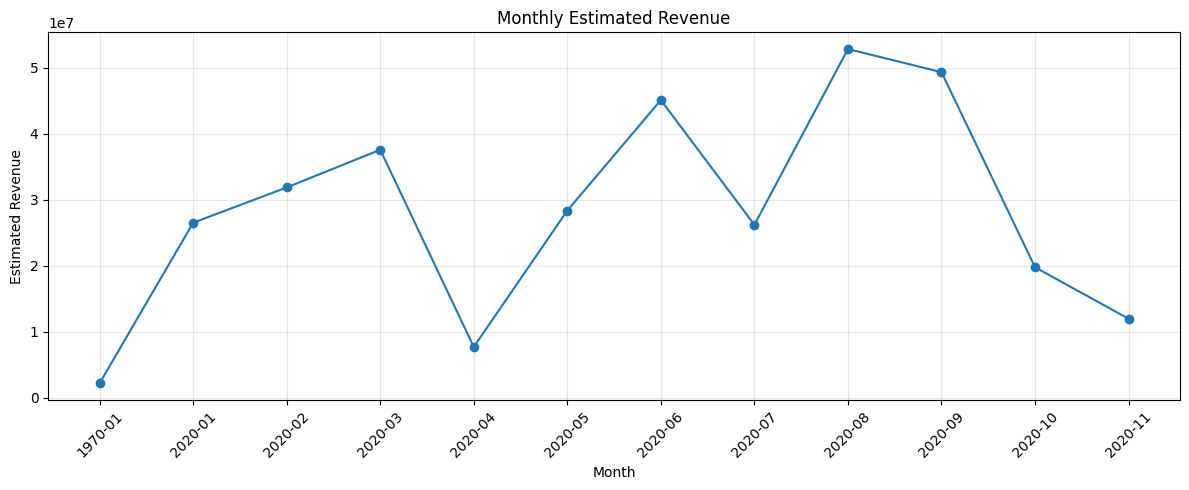

In [109]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Estimated_Revenue"],
    marker="o"
)

plt.title("Monthly Estimated Revenue")
plt.xlabel("Month")
plt.ylabel("Estimated Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [110]:
brand_data = analysis_df.dropna(
    subset=["brand"]
).copy()

brand_summary = (
    brand_data.groupby("brand")
    .agg(
        Purchase_Records=("product_id", "size"),
        Estimated_Revenue=("price", "sum"),
        Unique_Customers=("user_id", "nunique")
    )
    .reset_index()
)

brand_summary = brand_summary.sort_values(
    "Estimated_Revenue",
    ascending=False
)

top_10_brands = brand_summary.head(10)

display(top_10_brands)

,brand,Purchase_Records,Estimated_Revenue,Unique_Customers
709,samsung,358809,90024615.05,35646
45,apple,74684,47893470.39,18772
475,lg,55663,26148633.49,8386
128,bosch,33887,11075932.70,4755
372,huawei,57428,10772736.47,5729
63,asus,20590,10634387.10,5713
472,lenovo,19652,10525822.64,4863
72,ava,118128,8540869.03,11740
94,beko,32139,8480997.57,4959
603,oppo,36441,7321375.45,3300


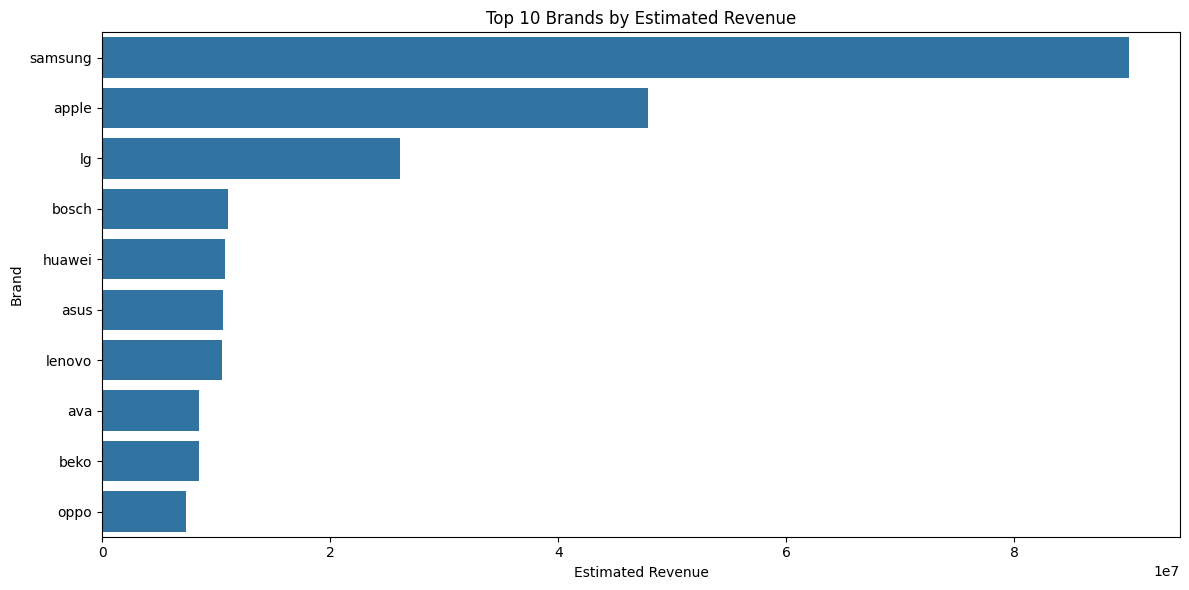

In [111]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_brands,
    x="Estimated_Revenue",
    y="brand"
)

plt.title("Top 10 Brands by Estimated Revenue")
plt.xlabel("Estimated Revenue")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

In [112]:
analysis_df["Category"] = (
    analysis_df["category_code"]
    .fillna("Unknown")
    .astype(str)
    .str.split(".")
    .str[0]
)

category_summary = (
    analysis_df.groupby("Category")
    .agg(
        Purchase_Records=("product_id", "size"),
        Estimated_Revenue=("price", "sum"),
        Unique_Customers=("user_id", "nunique")
    )
    .reset_index()
    .sort_values("Estimated_Revenue", ascending=False)
)

display(category_summary.head(15))

,Category,Purchase_Records,Estimated_Revenue,Unique_Customers
8,electronics,548883,1.483383e+08,55945
3,appliances,608716,1.035991e+08,42468
5,computers,222519,4.183043e+07,26677
0,Unknown,611966,3.626633e+07,31585
9,furniture,121343,4.042731e+06,7264
2,apparel,7726,1.962861e+06,1587
10,kids,4996,1.114860e+06,1595
6,construction,12608,4.608675e+05,2439
12,sport,1899,4.459513e+05,635
4,auto,3258,3.163366e+05,999


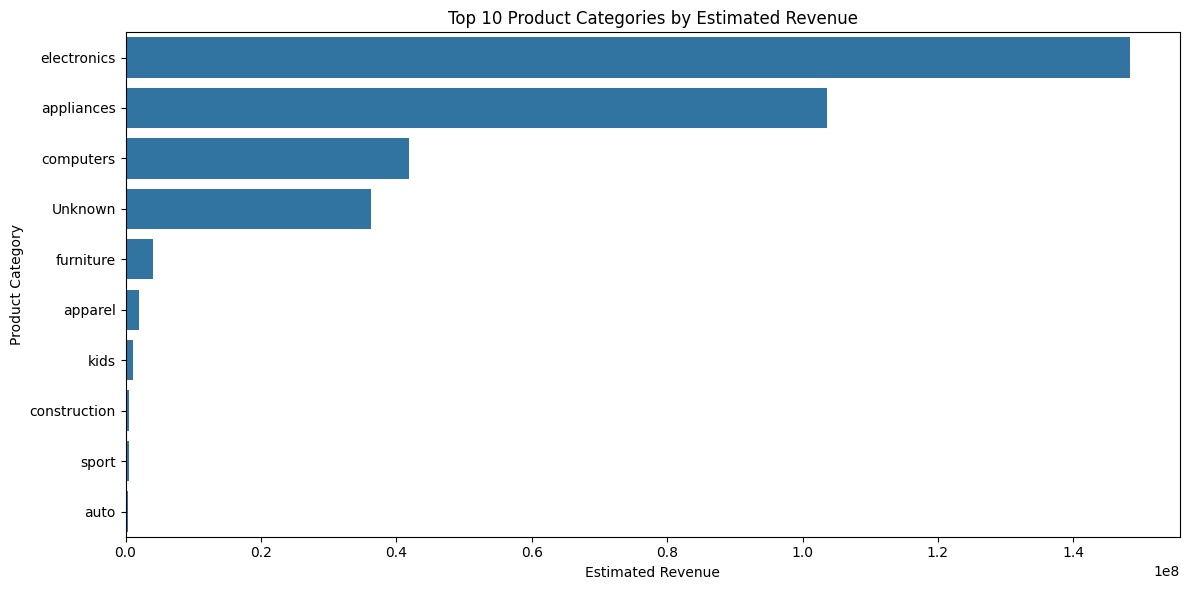

In [113]:
top_categories = category_summary.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x="Estimated_Revenue",
    y="Category"
)

plt.title("Top 10 Product Categories by Estimated Revenue")
plt.xlabel("Estimated Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [114]:
print("Mean price:", round(analysis_df["price"].mean(), 2))
print("Median price:", round(analysis_df["price"].median(), 2))
print("Minimum price:", round(analysis_df["price"].min(), 2))
print("Maximum price:", round(analysis_df["price"].max(), 2))

display(analysis_df["price"].describe())

Mean price: 154.1
Median price: 55.53
Minimum price: 0.02
Maximum price: 50925.9


,price
count,2.200772e+06
mean,1.540997e+02
std,2.419364e+02
min,2.000000e-02
25%,1.456000e+01
50%,5.553000e+01
75%,1.967400e+02
max,5.092590e+04


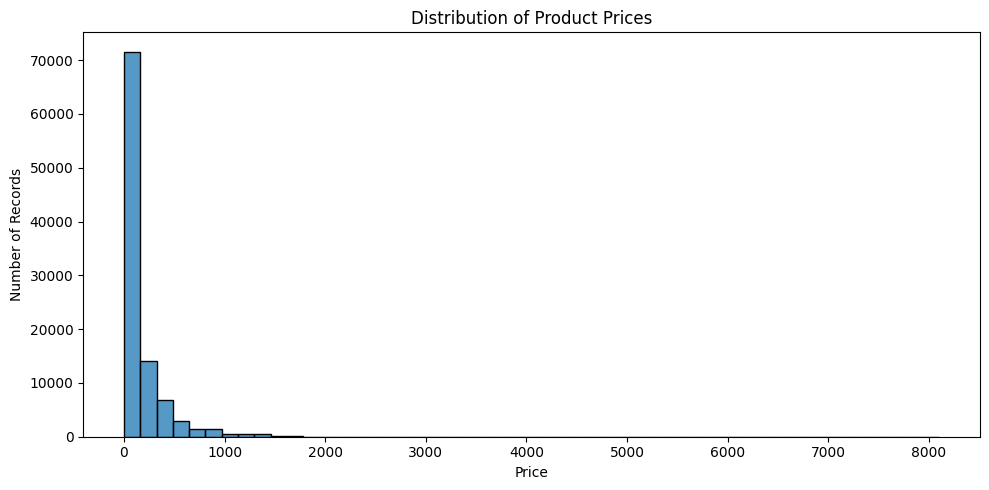

In [115]:
price_sample = analysis_df["price"].sample(
    n=min(100000, len(analysis_df)),
    random_state=42
)

plt.figure(figsize=(10, 5))

sns.histplot(
    price_sample,
    bins=50
)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

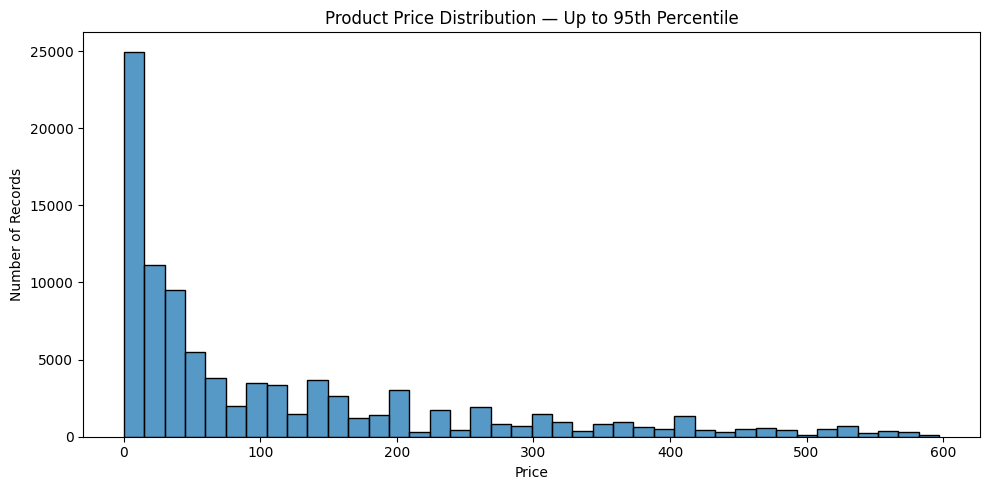

In [116]:
price_limit = analysis_df["price"].quantile(0.95)

price_sample_95 = price_sample[
    price_sample <= price_limit
]

plt.figure(figsize=(10, 5))

sns.histplot(
    price_sample_95,
    bins=40
)

plt.title("Product Price Distribution — Up to 95th Percentile")
plt.xlabel("Price")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [117]:
monthly_sales.to_csv(
    "monthly_sales_analysis.csv",
    index=False
)

brand_summary.to_csv(
    "brand_performance_analysis.csv",
    index=False
)

category_summary.to_csv(
    "category_performance_analysis.csv",
    index=False
)

print("EDA result files saved successfully.")

EDA result files saved successfully.


In [118]:

# Step 1: Check the data required for customer analytics

required_columns = [
    "event_time",
    "order_id",
    "price",
    "user_id"
]

print("Available columns:")
print(analysis_df.columns.tolist())

missing_columns = [
    col for col in required_columns
    if col not in analysis_df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("\nRequired columns are available.")
print("Dataset shape:", analysis_df.shape)

display(analysis_df[required_columns].head())


Available columns:
['event_time', 'order_id', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'Month', 'Category']

Required columns are available.
Dataset shape: (2200772, 10)


,event_time,order_id,price,user_id
0,2020-04-24 11:50:39+00:00,2294359932054536986,162.01,1.515916e+18
2,2020-04-24 14:37:43+00:00,2294444024058086220,77.52,1.515916e+18
4,2020-04-24 19:16:21+00:00,2294584263154074236,217.57,1.515916e+18
5,2020-04-26 08:45:57+00:00,2295716521449619559,39.33,1.515916e+18
6,2020-04-26 09:33:47+00:00,2295740594749702229,1387.01,1.515916e+18


In [119]:

# Step 2: Prepare order-level data

customer_data = analysis_df.copy()

customer_data["event_time"] = pd.to_datetime(
    customer_data["event_time"],
    errors="coerce",
    utc=True
)

customer_data["price"] = pd.to_numeric(
    customer_data["price"],
    errors="coerce"
)

customer_data = customer_data.dropna(
    subset=["event_time", "order_id", "user_id", "price"]
)

customer_data = customer_data[
    (customer_data["price"] > 0) &
    (customer_data["order_id"].notna()) &
    (customer_data["user_id"].notna())
].copy()

order_data = (
    customer_data
    .groupby(["user_id", "order_id"], as_index=False)
    .agg(
        order_date=("event_time", "min"),
        order_value=("price", "sum")
    )
)

print("Total customers:", order_data["user_id"].nunique())
print("Total unique orders:", order_data["order_id"].nunique())

display(order_data.head())


Total customers: 98257
Total unique orders: 400516


,user_id,order_id,order_date,order_value
0,1.515916e+18,2349284169969828321,2020-07-09 06:35:18+00:00,416.64
1,1.515916e+18,2388440981134512449,2020-09-22 15:11:15+00:00,21.04
2,1.515916e+18,2388440981134640159,2020-10-28 05:53:47+00:00,35.39
3,1.515916e+18,2388440981134625646,2020-10-21 12:23:18+00:00,40.81
4,1.515916e+18,2388440981134632037,2020-10-23 03:51:26+00:00,115.72


In [120]:

# Step 3: Analyze repeat purchases

customer_purchase_counts = (
    order_data.groupby("user_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_spending=("order_value", "sum")
    )
    .reset_index()
)

customer_purchase_counts["purchase_type"] = (
    customer_purchase_counts["total_orders"]
    .apply(
        lambda x: "Repeat Customer"
        if x > 1 else "One-Time Customer"
    )
)

purchase_summary = (
    customer_purchase_counts["purchase_type"]
    .value_counts()
    .rename_axis("Customer Type")
    .reset_index(name="Number of Customers")
)

purchase_summary["Percentage"] = (
    purchase_summary["Number of Customers"]
    / purchase_summary["Number of Customers"].sum()
    * 100
)

print("Repeat Purchase Summary")
display(purchase_summary.round(2))


Repeat Purchase Summary


,Customer Type,Number of Customers,Percentage
0,Repeat Customer,54275,55.24
1,One-Time Customer,43982,44.76


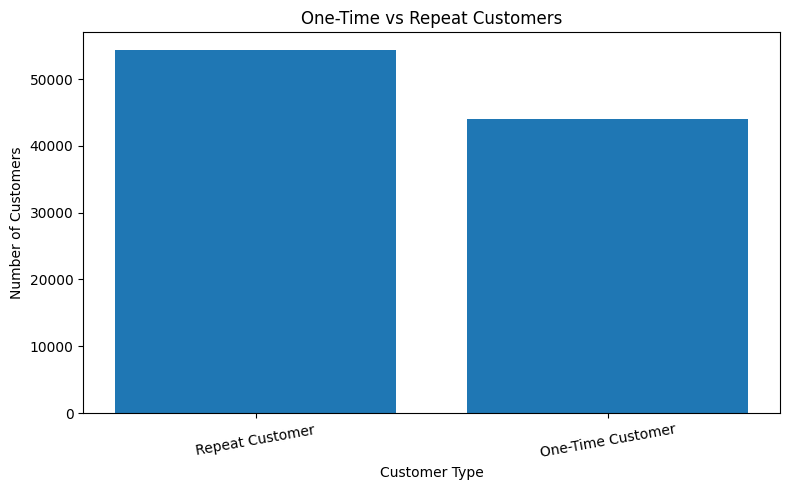

In [121]:

# Step 4: Plot customer purchase types

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    purchase_summary["Customer Type"],
    purchase_summary["Number of Customers"]
)

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


In [122]:

# Step 5A: Calculate RFM metrics

reference_date = (
    order_data["order_date"].max()
    + pd.Timedelta(days=1)
)

rfm = (
    order_data.groupby("user_id")
    .agg(
        Last_Purchase=("order_date", "max"),
        Frequency=("order_id", "nunique"),
        Monetary=("order_value", "sum")
    )
    .reset_index()
)

rfm["Recency"] = (
    reference_date - rfm["Last_Purchase"]
).dt.days

rfm = rfm[
    ["user_id", "Recency", "Frequency", "Monetary"]
]

print("RFM Analysis Results")
display(rfm.head(10))

print("\nRFM Summary")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())


RFM Analysis Results


,user_id,Recency,Frequency,Monetary
0,1.515916e+18,136,1,416.64
1,1.515916e+18,25,2,56.43
2,1.515916e+18,5,5,7530.34
3,1.515916e+18,13,19,4935.60
4,1.515916e+18,130,2,182.83
5,1.515916e+18,5,36,22916.99
6,1.515916e+18,15,10,5005.55
7,1.515916e+18,66,23,12186.27
8,1.515916e+18,6,10,10563.41
9,1.515916e+18,7,31,10936.89



RFM Summary


,Recency,Frequency,Monetary
count,98257.000000,98257.000000,98257.000000
mean,102.926723,4.076208,1194.733424
std,256.107779,16.540284,3837.875024
min,1.000000,1.000000,0.020000
25%,62.000000,1.000000,138.870000
50%,102.000000,2.000000,431.830000
75%,128.000000,3.000000,1092.510000
max,18588.000000,402.000000,121701.300000


In [123]:

# Step 5B: Assign RFM scores

def assign_score(series, higher_is_better=True):
    ranks = series.rank(
        method="first",
        ascending=higher_is_better
    )

    return (
        pd.qcut(
            ranks,
            q=5,
            labels=[1, 2, 3, 4, 5]
        )
        .astype(int)
    )

rfm["R_Score"] = assign_score(
    rfm["Recency"],
    higher_is_better=False
)

rfm["F_Score"] = assign_score(
    rfm["Frequency"],
    higher_is_better=True
)

rfm["M_Score"] = assign_score(
    rfm["Monetary"],
    higher_is_better=True
)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

display(rfm.sort_values(
    ["R_Score", "F_Score", "M_Score"],
    ascending=False
).head(10))


,user_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
2,1.515916e+18,5,5,7530.34,5,5,5,555
3,1.515916e+18,13,19,4935.60,5,5,5,555
5,1.515916e+18,5,36,22916.99,5,5,5,555
6,1.515916e+18,15,10,5005.55,5,5,5,555
8,1.515916e+18,6,10,10563.41,5,5,5,555
9,1.515916e+18,7,31,10936.89,5,5,5,555
10,1.515916e+18,4,14,5023.97,5,5,5,555
13,1.515916e+18,24,8,3646.54,5,5,5,555
21,1.515916e+18,28,12,2453.84,5,5,5,555
24,1.515916e+18,12,13,4270.51,5,5,5,555


In [124]:

# Step 5C: Create customer segments

def classify_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4:
        return "Loyal Active Customers"

    elif row["R_Score"] >= 4 and row["M_Score"] >= 4:
        return "Recent High-Value Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 4:
        return "At-Risk Loyal Customers"

    elif row["R_Score"] <= 2:
        return "Inactive-Risk Customers"

    elif row["F_Score"] <= 2:
        return "Low-Frequency Customers"

    else:
        return "Regular Customers"

rfm["Customer_Segment"] = rfm.apply(
    classify_customer,
    axis=1
)

segment_summary = (
    rfm.groupby("Customer_Segment")
    .agg(
        Customers=("user_id", "nunique"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean")
    )
    .reset_index()
)

display(segment_summary.round(2))


,Customer_Segment,Customers,Average_Recency,Average_Frequency,Average_Monetary
0,At-Risk Loyal Customers,6422,135.11,4.06,1178.05
1,Inactive-Risk Customers,32881,164.57,1.24,324.49
2,Low-Frequency Customers,13287,86.01,1.00,287.53
3,Loyal Active Customers,24441,43.79,10.89,3060.20
4,Recent High-Value Customers,3524,51.39,1.44,1166.66
5,Regular Customers,17702,81.35,2.78,928.15


In [125]:

# Step 6A: Prepare cohort data

cohort_data = order_data.copy()

cohort_data["order_date"] = (
    cohort_data["order_date"]
    .dt.tz_localize(None)
)

cohort_data["Order_Month"] = (
    cohort_data["order_date"].dt.to_period("M")
)

first_purchase = (
    cohort_data.groupby("user_id")["Order_Month"]
    .min()
    .rename("Cohort_Month")
)

cohort_data = cohort_data.join(
    first_purchase,
    on="user_id"
)

cohort_data["Cohort_Index"] = (
    (cohort_data["Order_Month"].dt.year
     - cohort_data["Cohort_Month"].dt.year) * 12
    + cohort_data["Order_Month"].dt.month
    - cohort_data["Cohort_Month"].dt.month
    + 1
)

print("Cohort data prepared.")
display(cohort_data.head(10))


Cohort data prepared.


,user_id,order_id,order_date,order_value,Order_Month,Cohort_Month,Cohort_Index
0,1.515916e+18,2349284169969828321,2020-07-09 06:35:18,416.64,2020-07,2020-07,1
1,1.515916e+18,2388440981134512449,2020-09-22 15:11:15,21.04,2020-09,2020-09,1
2,1.515916e+18,2388440981134640159,2020-10-28 05:53:47,35.39,2020-10,2020-09,2
3,1.515916e+18,2388440981134625646,2020-10-21 12:23:18,40.81,2020-10,2020-10,1
4,1.515916e+18,2388440981134632037,2020-10-23 03:51:26,115.72,2020-10,2020-10,1
5,1.515916e+18,2388440981134632210,2020-10-23 06:38:11,428.22,2020-10,2020-10,1
6,1.515916e+18,2388440981134632236,2020-10-23 07:02:33,428.22,2020-10,2020-10,1
7,1.515916e+18,2388440981134675355,2020-11-16 15:49:50,6517.37,2020-11,2020-10,2
8,1.515916e+18,2313770336769802965,2020-05-21 06:35:39,624.98,2020-05,2020-05,1
9,1.515916e+18,2354506365080174801,2020-05-12 05:56:43,16.18,2020-05,2020-05,1


In [126]:

# Step 6B: Calculate monthly cohort retention

cohort_counts = cohort_data.pivot_table(
    index="Cohort_Month",
    columns="Cohort_Index",
    values="user_id",
    aggfunc="nunique"
)

cohort_sizes = cohort_counts.iloc[:, 0]

retention = cohort_counts.divide(
    cohort_sizes,
    axis=0
) * 100

print("Customer Retention (%)")
display(retention.round(2))


Customer Retention (%)


Cohort_Index,1,2,3,4,5,6,7,8,9,10,...,602,603,604,605,606,607,608,609,610,611
Cohort_Month,,,,,,,,,,,,,,,,,,,,,
1970-01,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,31.55,29.17,22.02,42.86,37.5,40.48,43.45,35.12,21.43,17.26
2020-01,100.0,34.01,31.06,25.59,42.86,42.54,38.05,41.12,36.09,23.24,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-02,100.0,31.71,23.75,40.83,40.77,37.79,40.10,35.12,20.66,17.38,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-03,100.0,25.36,42.62,42.29,36.89,39.92,35.77,20.82,13.83,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-04,100.0,25.99,16.74,23.33,22.92,16.49,11.33,6.34,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-05,100.0,14.65,18.43,18.03,12.06,7.69,4.18,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-06,100.0,23.42,20.11,13.43,8.73,5.03,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-07,100.0,23.59,10.84,6.75,3.35,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-08,100.0,14.84,8.82,4.79,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


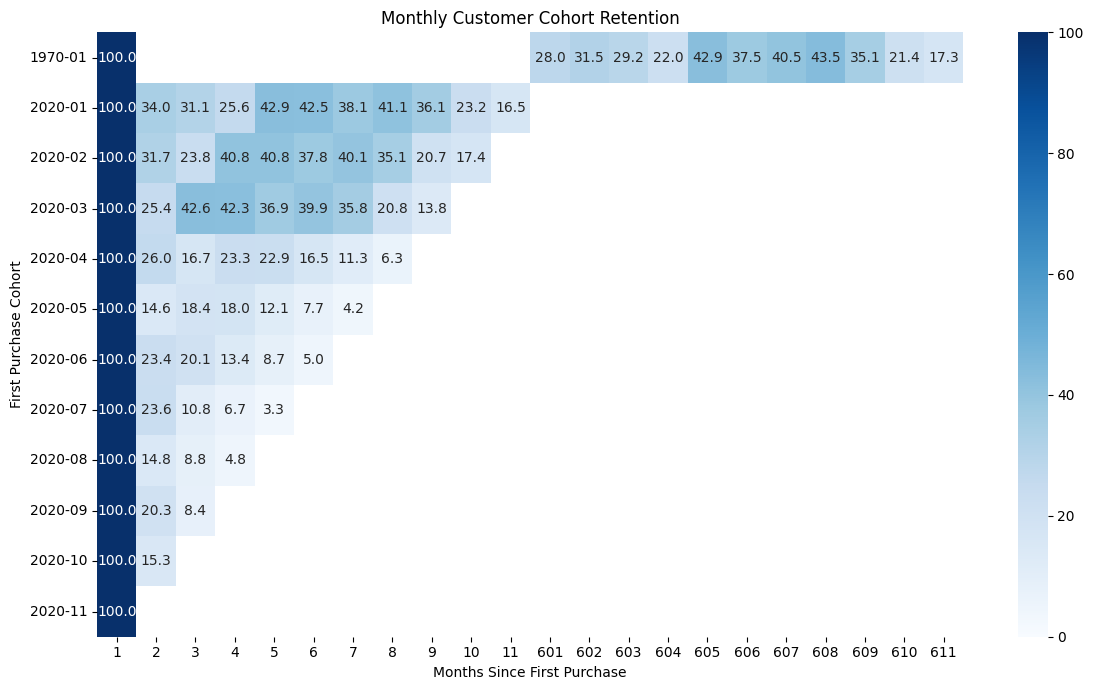

In [127]:

# Step 6C: Visualize cohort retention

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

sns.heatmap(
    retention,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("Monthly Customer Cohort Retention")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First Purchase Cohort")
plt.tight_layout()
plt.show()


In [128]:

# Step 7: Identify inactivity-risk customers

rfm["Inactivity_Risk"] = pd.cut(
    rfm["Recency"],
    bins=[-1, 30, 60, 90, float("inf")],
    labels=[
        "Recently Active",
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ]
)

risk_summary = (
    rfm.groupby(
        "Inactivity_Risk",
        observed=False
    )
    .agg(
        Number_of_Customers=("user_id", "nunique"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean")
    )
    .reset_index()
)

display(risk_summary.round(2))


,Inactivity_Risk,Number_of_Customers,Average_Recency,Average_Frequency,Average_Monetary
0,Recently Active,12446,13.82,15.02,3861.20
1,Low Risk,11551,45.37,4.29,1395.78
2,Medium Risk,16398,76.15,3.16,1111.23
3,High Risk,57862,141.17,1.94,604.71


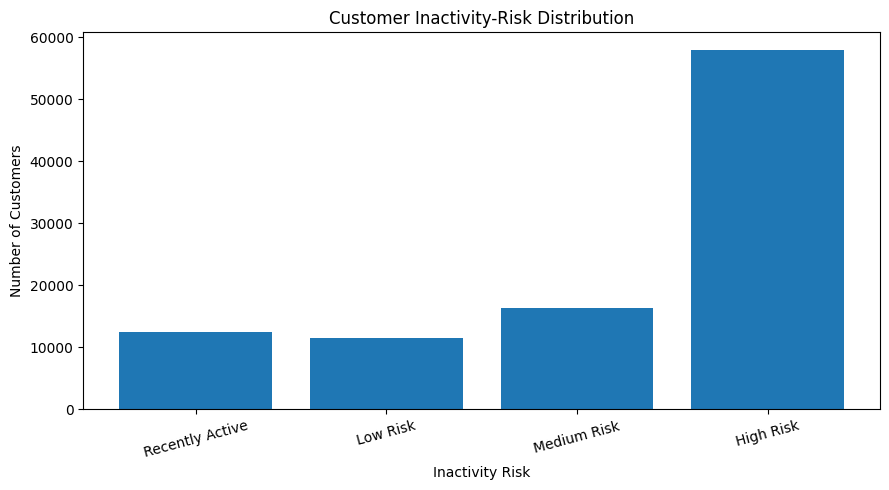

In [129]:

# Step 7B: Plot inactivity-risk distribution

plt.figure(figsize=(9, 5))

plt.bar(
    risk_summary["Inactivity_Risk"].astype(str),
    risk_summary["Number_of_Customers"]
)

plt.title("Customer Inactivity-Risk Distribution")
plt.xlabel("Inactivity Risk")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [130]:

# Step 8: Export customer analytics results

customer_purchase_counts.to_csv(
    "repeat_purchase_analysis.csv",
    index=False
)

rfm.to_csv(
    "customer_rfm_and_risk_analysis.csv",
    index=False
)

segment_summary.to_csv(
    "customer_segment_summary.csv",
    index=False
)

retention.to_csv(
    "customer_cohort_retention.csv"
)

print("All customer analytics files have been saved.")


All customer analytics files have been saved.


In [131]:

advanced_df = analysis_df.copy()

print(advanced_df.shape)
print(advanced_df.columns.tolist())


(2200772, 10)
['event_time', 'order_id', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'Month', 'Category']


In [132]:

advanced_df["event_time"] = pd.to_datetime(
    advanced_df["event_time"],
    errors="coerce",
    utc=True
)

advanced_df["price"] = pd.to_numeric(
    advanced_df["price"],
    errors="coerce"
)

print("Data prepared successfully.")


Data prepared successfully.


In [133]:

brand_data = advanced_df.dropna(
    subset=["user_id", "order_id", "event_time", "brand"]
).copy()

brand_data["brand"] = (
    brand_data["brand"].astype(str).str.strip()
)

brand_data = brand_data[
    (brand_data["brand"] != "") &
    (brand_data["brand"].str.lower() != "nan")
]

display(brand_data.head())


,event_time,order_id,product_id,category_id,category_code,brand,price,user_id,Month,Category
0,2020-04-24 11:50:39+00:00,2294359932054536986,1515966223509089906,2.268105e+18,electronics.tablet,samsung,162.01,1.515916e+18,2020-04,electronics
2,2020-04-24 14:37:43+00:00,2294444024058086220,2273948319057183658,2.268105e+18,electronics.audio.headphone,huawei,77.52,1.515916e+18,2020-04,electronics
4,2020-04-24 19:16:21+00:00,2294584263154074236,2273948316817424439,2.268105e+18,NaN,karcher,217.57,1.515916e+18,2020-04,Unknown
5,2020-04-26 08:45:57+00:00,2295716521449619559,1515966223509261697,2.268105e+18,furniture.kitchen.table,maestro,39.33,1.515916e+18,2020-04,furniture
6,2020-04-26 09:33:47+00:00,2295740594749702229,1515966223509104892,2.268105e+18,electronics.smartphone,apple,1387.01,1.515916e+18,2020-04,electronics


In [134]:

brand_order = (
    brand_data.groupby(["user_id", "order_id"])
    .agg(
        order_date=("event_time", "min"),
        brand_count=("brand", "nunique"),
        brand=("brand", "first")
    )
    .reset_index()
)

brand_order = brand_order[
    brand_order["brand_count"] == 1
].copy()

print("Total orders:", len(brand_order))
display(brand_order.head())


Total orders: 319953


,user_id,order_id,order_date,brand_count,brand
0,1.515916e+18,2349284169969828321,2020-07-09 06:35:18+00:00,1,lg
1,1.515916e+18,2388440981134512449,2020-09-22 15:11:15+00:00,1,transcend
2,1.515916e+18,2388440981134640159,2020-10-28 05:53:47+00:00,1,asus
3,1.515916e+18,2388440981134632037,2020-10-23 03:51:26+00:00,1,ava
4,1.515916e+18,2388440981134632210,2020-10-23 06:38:11+00:00,1,samsung


In [135]:

brand_order = brand_order.sort_values(
    ["user_id", "order_date", "order_id"]
)

brand_order["Previous_Brand"] = (
    brand_order.groupby("user_id")["brand"].shift(1)
)

brand_order["Brand_Switch"] = (
    brand_order["Previous_Brand"].notna() &
    (brand_order["brand"] != brand_order["Previous_Brand"])
)

switch_records = brand_order[
    brand_order["Brand_Switch"]
].copy()

print("Total brand switches:", len(switch_records))
display(switch_records.head(10))


Total brand switches: 173323


,user_id,order_id,order_date,brand_count,brand,Previous_Brand,Brand_Switch
2,1.515916e+18,2388440981134640159,2020-10-28 05:53:47+00:00,1,asus,transcend,True
4,1.515916e+18,2388440981134632210,2020-10-23 06:38:11+00:00,1,samsung,ava,True
8,1.515916e+18,2354508977594696516,2020-05-21 21:15:10+00:00,1,ava,canon,True
9,1.515916e+18,2354515508478345758,2020-06-10 21:37:30+00:00,1,apple,ava,True
10,1.515916e+18,2357969000991817755,2020-07-14 23:55:17+00:00,1,casio,apple,True
12,1.515916e+18,2388440981134546657,2020-09-25 09:30:19+00:00,1,whirlpool,casio,True
13,1.515916e+18,2388440981134553438,2020-09-29 09:35:33+00:00,1,kaabo,whirlpool,True
14,1.515916e+18,2388440981134589550,2020-10-06 05:59:30+00:00,1,samsung,kaabo,True
15,1.515916e+18,2388440981134605273,2020-10-12 03:40:07+00:00,1,nordland,samsung,True
19,1.515916e+18,2388440981134632176,2020-10-23 05:53:27+00:00,1,yokohama,nordland,True


In [136]:

brand_transitions = (
    switch_records.groupby(
        ["Previous_Brand", "brand"]
    )
    .size()
    .reset_index(name="Switch_Count")
    .sort_values("Switch_Count", ascending=False)
)

display(brand_transitions.head(10))


,Previous_Brand,brand,Switch_Count
1343,apple,samsung,2572
19892,samsung,apple,2531
19908,samsung,ava,1783
2532,ava,samsung,1749
20365,samsung,xiaomi,1168
13481,lg,samsung,1119
20314,samsung,tefal,1106
20136,samsung,lg,1078
22476,tefal,samsung,1072
25245,xiaomi,samsung,1050


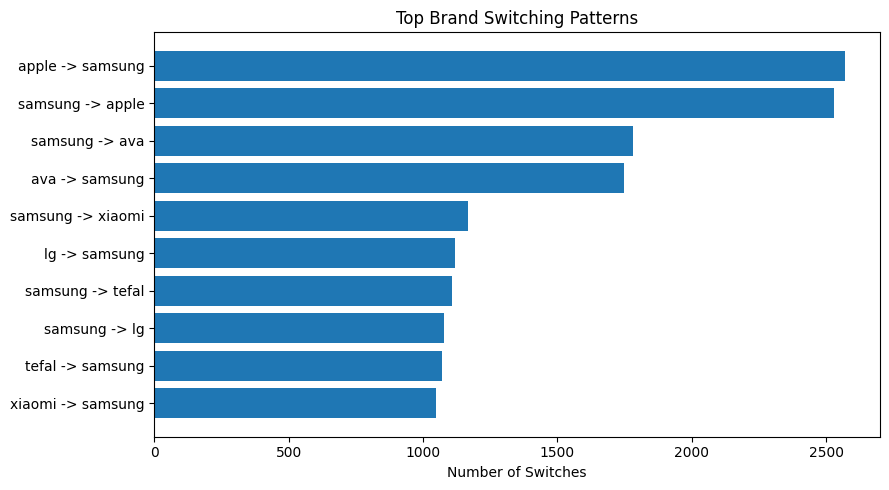

In [137]:

top_brands = brand_transitions.head(10).copy()

top_brands["Transition"] = (
    top_brands["Previous_Brand"]
    + " -> "
    + top_brands["brand"]
)

plt.figure(figsize=(9, 5))

plt.barh(
    top_brands["Transition"],
    top_brands["Switch_Count"]
)

plt.gca().invert_yaxis()
plt.title("Top Brand Switching Patterns")
plt.xlabel("Number of Switches")
plt.tight_layout()
plt.show()


In [140]:

order_data["order_date"] = pd.to_datetime(
    order_data["order_date"],
    errors="coerce",
    utc=True
)

reference_date = (
    order_data["order_date"].max()
    + pd.Timedelta(days=1)
)


In [141]:

customer_features = (
    order_data.groupby("user_id")
    .agg(
        Last_Order_Date=("order_date", "max"),
        Total_Orders=("order_id", "nunique"),
        Total_Spending=("order_value", "sum"),
        Average_Order_Value=("order_value", "mean")
    )
    .reset_index()
)

customer_features["Recency_Days"] = (
    reference_date - customer_features["Last_Order_Date"]
).dt.days

display(customer_features.head())


,user_id,Last_Order_Date,Total_Orders,Total_Spending,Average_Order_Value,Recency_Days
0,1.515916e+18,2020-07-09 06:35:18+00:00,1,416.64,416.640000,136
1,1.515916e+18,2020-10-28 05:53:47+00:00,2,56.43,28.215000,25
2,1.515916e+18,2020-11-16 15:49:50+00:00,5,7530.34,1506.068000,5
3,1.515916e+18,2020-11-08 23:48:43+00:00,19,4935.60,259.768421,13
4,1.515916e+18,2020-07-14 13:04:12+00:00,2,182.83,91.415000,130


In [142]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

feature_columns = [
    "Recency_Days",
    "Total_Orders",
    "Total_Spending",
    "Average_Order_Value"
]

X = customer_features[feature_columns].copy()

X["Total_Spending"] = np.log1p(
    X["Total_Spending"].clip(lower=0)
)

X["Average_Order_Value"] = np.log1p(
    X["Average_Order_Value"].clip(lower=0)
)

print(X.head())


   Recency_Days  Total_Orders  Total_Spending  Average_Order_Value
0           136             1        6.034620             6.034620
1            25             2        4.050567             3.374682
2             5             5        8.926828             7.317921
3            13            19        8.504432             5.563633
4           130             2        5.214011             4.526289


In [143]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed.")
print("Shape:", X_scaled.shape)


Feature scaling completed.
Shape: (98257, 4)


In [144]:

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_features["Cluster"] = (
    kmeans.fit_predict(X_scaled)
)

display(customer_features.head(10))


,user_id,Last_Order_Date,Total_Orders,Total_Spending,Average_Order_Value,Recency_Days,Cluster
0,1.515916e+18,2020-07-09 06:35:18+00:00,1,416.64,416.640000,136,0
1,1.515916e+18,2020-10-28 05:53:47+00:00,2,56.43,28.215000,25,1
2,1.515916e+18,2020-11-16 15:49:50+00:00,5,7530.34,1506.068000,5,0
3,1.515916e+18,2020-11-08 23:48:43+00:00,19,4935.60,259.768421,13,0
4,1.515916e+18,2020-07-14 13:04:12+00:00,2,182.83,91.415000,130,1
5,1.515916e+18,2020-11-16 10:27:57+00:00,36,22916.99,636.583056,5,0
6,1.515916e+18,2020-11-06 14:52:05+00:00,10,5005.55,500.555000,15,0
7,1.515916e+18,2020-09-16 10:35:47+00:00,23,12186.27,529.837826,66,0
8,1.515916e+18,2020-11-15 12:04:38+00:00,10,10563.41,1056.341000,6,0
9,1.515916e+18,2020-11-14 12:46:44+00:00,31,10936.89,352.802903,7,0


In [145]:

cluster_summary = (
    customer_features.groupby("Cluster")
    .agg(
        Customer_Count=("user_id", "nunique"),
        Average_Recency=("Recency_Days", "mean"),
        Average_Orders=("Total_Orders", "mean"),
        Average_Spending=("Total_Spending", "mean")
    )
    .reset_index()
)

display(cluster_summary.round(2))


,Cluster,Customer_Count,Average_Recency,Average_Orders,Average_Spending
0,0,67518,90.80,3.63,1355.52
1,1,30178,120.78,1.53,87.16
2,2,18,18588.00,1.06,157.14
3,3,543,5.73,201.39,42791.77


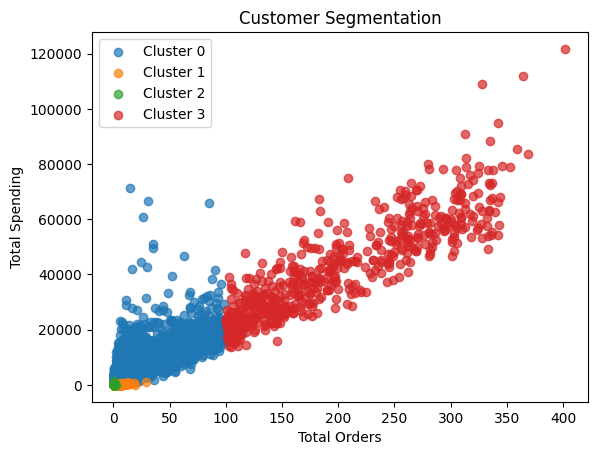

In [146]:

for cluster_id in sorted(
    customer_features["Cluster"].unique()
):
    subset = customer_features[
        customer_features["Cluster"] == cluster_id
    ]

    plt.scatter(
        subset["Total_Orders"],
        subset["Total_Spending"],
        label=f"Cluster {cluster_id}",
        alpha=0.7
    )

plt.title("Customer Segmentation")
plt.xlabel("Total Orders")
plt.ylabel("Total Spending")
plt.legend()
plt.show()


In [147]:

purchase_history = (
    order_data[
        ["user_id", "order_id", "order_date", "order_value"]
    ]
    .drop_duplicates(["user_id", "order_id"])
    .sort_values(["user_id", "order_date", "order_id"])
    .copy()
)

display(purchase_history.head())


,user_id,order_id,order_date,order_value
0,1.515916e+18,2349284169969828321,2020-07-09 06:35:18+00:00,416.64
1,1.515916e+18,2388440981134512449,2020-09-22 15:11:15+00:00,21.04
2,1.515916e+18,2388440981134640159,2020-10-28 05:53:47+00:00,35.39
3,1.515916e+18,2388440981134625646,2020-10-21 12:23:18+00:00,40.81
4,1.515916e+18,2388440981134632037,2020-10-23 03:51:26+00:00,115.72


In [148]:

purchase_history["Previous_Order_Date"] = (
    purchase_history.groupby("user_id")["order_date"].shift(1)
)

purchase_history["Days_Between_Orders"] = (
    purchase_history["order_date"]
    - purchase_history["Previous_Order_Date"]
).dt.total_seconds() / 86400

purchase_gaps = purchase_history.dropna(
    subset=["Days_Between_Orders"]
).copy()

display(purchase_gaps.head(10))


,user_id,order_id,order_date,order_value,Previous_Order_Date,Days_Between_Orders
2,1.515916e+18,2388440981134640159,2020-10-28 05:53:47+00:00,35.39,2020-09-22 15:11:15+00:00,35.612870
4,1.515916e+18,2388440981134632037,2020-10-23 03:51:26+00:00,115.72,2020-10-21 12:23:18+00:00,1.644537
5,1.515916e+18,2388440981134632210,2020-10-23 06:38:11+00:00,428.22,2020-10-23 03:51:26+00:00,0.115799
6,1.515916e+18,2388440981134632236,2020-10-23 07:02:33+00:00,428.22,2020-10-23 06:38:11+00:00,0.016921
7,1.515916e+18,2388440981134675355,2020-11-16 15:49:50+00:00,6517.37,2020-10-23 07:02:33+00:00,24.366169
8,1.515916e+18,2313770336769802965,2020-05-21 06:35:39+00:00,624.98,2020-05-12 05:56:43+00:00,9.027037
10,1.515916e+18,2354508977594696516,2020-05-21 21:15:10+00:00,2.29,2020-05-21 06:35:39+00:00,0.610775
11,1.515916e+18,2354515508478345758,2020-06-10 21:37:30+00:00,324.05,2020-05-21 21:15:10+00:00,20.015509
13,1.515916e+18,2357969000991817755,2020-07-14 23:55:17+00:00,1144.65,2020-06-10 21:37:30+00:00,34.095683
12,1.515916e+18,2357968275771490918,2020-07-15 03:15:42+00:00,115.72,2020-07-14 23:55:17+00:00,0.139178


In [149]:

customer_intervals = (
    purchase_gaps.groupby("user_id")
    .agg(
        Median_Gap_Days=("Days_Between_Orders", "median"),
        Average_Gap_Days=("Days_Between_Orders", "mean"),
        Last_Order_Date=("order_date", "max")
    )
    .reset_index()
)

display(customer_intervals.head(10))


,user_id,Median_Gap_Days,Average_Gap_Days,Last_Order_Date
0,1.515916e+18,35.612870,35.612870,2020-10-28 05:53:47+00:00
1,1.515916e+18,0.880168,6.535856,2020-11-16 15:49:50+00:00
2,1.515916e+18,4.504068,10.041358,2020-11-08 23:48:43+00:00
3,1.515916e+18,58.871516,58.871516,2020-07-14 13:04:12+00:00
4,1.515916e+18,0.800949,5.134216,2020-11-16 10:27:57+00:00
5,1.515916e+18,2.087778,20.696008,2020-11-06 14:52:05+00:00
6,1.515916e+18,0.790637,9.550162,2020-09-16 10:35:47+00:00
7,1.515916e+18,8.974005,27.468011,2020-11-15 12:04:38+00:00
8,1.515916e+18,3.215284,8.734470,2020-11-14 12:46:44+00:00
9,1.515916e+18,6.582975,15.006344,2020-11-18 07:20:35+00:00


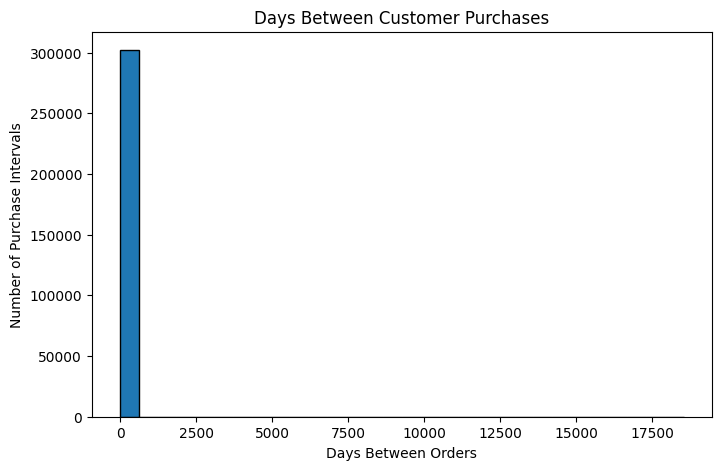

In [150]:

plt.figure(figsize=(8, 5))

plt.hist(
    purchase_gaps["Days_Between_Orders"].clip(lower=0),
    bins=30,
    edgecolor="black"
)

plt.title("Days Between Customer Purchases")
plt.xlabel("Days Between Orders")
plt.ylabel("Number of Purchase Intervals")
plt.show()


In [151]:

customer_intervals["Estimated_Next_Purchase"] = (
    customer_intervals["Last_Order_Date"]
    + pd.to_timedelta(
        customer_intervals["Median_Gap_Days"],
        unit="D"
    )
)

display(
    customer_intervals[
        [
            "user_id",
            "Median_Gap_Days",
            "Estimated_Next_Purchase"
        ]
    ].head(10)
)


,user_id,Median_Gap_Days,Estimated_Next_Purchase
0,1.515916e+18,35.612870,2020-12-02 20:36:19.000000002+00:00
1,1.515916e+18,0.880168,2020-11-17 12:57:16.500000002+00:00
2,1.515916e+18,4.504068,2020-11-13 11:54:34.499999996+00:00
3,1.515916e+18,58.871516,2020-09-11 09:59:10.999999999+00:00
4,1.515916e+18,0.800949,2020-11-17 05:41:19.000000002+00:00
5,1.515916e+18,2.087778,2020-11-08 16:58:29.000000001+00:00
6,1.515916e+18,0.790637,2020-09-17 05:34:18.000000002+00:00
7,1.515916e+18,8.974005,2020-11-24 11:27:11.999999997+00:00
8,1.515916e+18,3.215284,2020-11-17 17:56:44.499999998+00:00
9,1.515916e+18,6.582975,2020-11-24 21:20:03.999999996+00:00


In [152]:

brand_transitions.to_csv(
    "brand_switching_analysis.csv",
    index=False
)

customer_features.to_csv(
    "customer_segmentation_results.csv",
    index=False
)

customer_intervals.to_csv(
    "next_purchase_estimates.csv",
    index=False
)

print("Phase 4 files saved successfully.")


Phase 4 files saved successfully.


In [153]:

print("RFM data available:", "rfm" in globals())
print("Dataset available:", "analysis_df" in globals())


RFM data available: True
Dataset available: True


In [154]:

marketing_df = rfm.copy()

print("Total customer records:", len(marketing_df))
print(marketing_df.columns.tolist())


Total customer records: 98257
['user_id', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Customer_Segment', 'Inactivity_Risk']


In [155]:

display(
    marketing_df[
        ["user_id", "Recency", "Frequency",
         "Monetary", "R_Score", "F_Score", "M_Score"]
    ].head()
)


,user_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,1.515916e+18,136,1,416.64,2,1,3
1,1.515916e+18,25,2,56.43,5,3,1
2,1.515916e+18,5,5,7530.34,5,5,5
3,1.515916e+18,13,19,4935.60,5,5,5
4,1.515916e+18,130,2,182.83,2,3,2


In [156]:

def assign_segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4:
        return "Loyal Active Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 4:
        return "At-Risk Loyal Customers"
    elif row["R_Score"] <= 2:
        return "Inactive-Risk Customers"
    elif row["F_Score"] <= 2:
        return "Low-Frequency Customers"
    elif row["M_Score"] >= 4:
        return "High-Value Customers"
    else:
        return "Regular Customers"


In [157]:

marketing_df["Marketing_Segment"] = (
    marketing_df.apply(assign_segment, axis=1)
)

display(
    marketing_df[
        ["user_id", "Marketing_Segment"]
    ].head(10)
)


,user_id,Marketing_Segment
0,1.515916e+18,Inactive-Risk Customers
1,1.515916e+18,Regular Customers
2,1.515916e+18,Loyal Active Customers
3,1.515916e+18,Loyal Active Customers
4,1.515916e+18,Inactive-Risk Customers
5,1.515916e+18,Loyal Active Customers
6,1.515916e+18,Loyal Active Customers
7,1.515916e+18,Loyal Active Customers
8,1.515916e+18,Loyal Active Customers
9,1.515916e+18,Loyal Active Customers


In [158]:

segment_summary = (
    marketing_df["Marketing_Segment"]
    .value_counts()
    .reset_index()
)

segment_summary.columns = [
    "Customer_Segment",
    "Customer_Count"
]

display(segment_summary)


,Customer_Segment,Customer_Count
0,Inactive-Risk Customers,32881
1,Loyal Active Customers,24441
2,Low-Frequency Customers,14279
3,Regular Customers,10716
4,High-Value Customers,9518
5,At-Risk Loyal Customers,6422


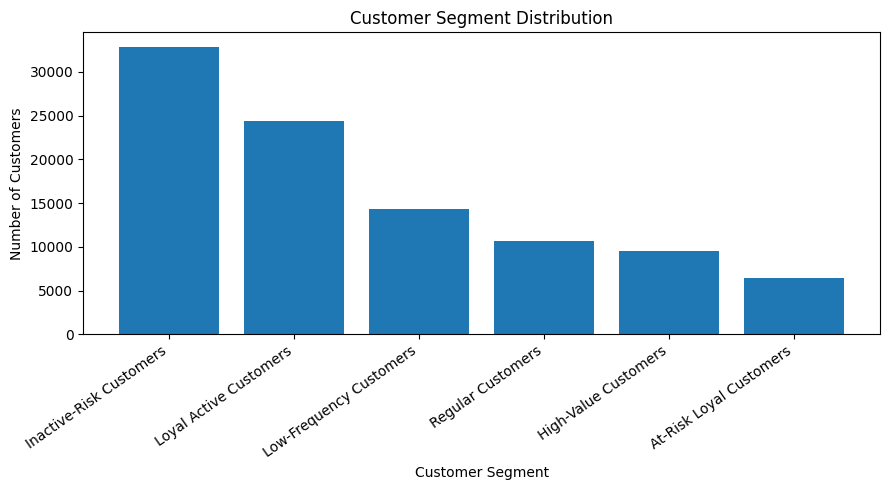

In [159]:

plt.figure(figsize=(9, 5))

plt.bar(
    segment_summary["Customer_Segment"],
    segment_summary["Customer_Count"]
)

plt.xticks(rotation=35, ha="right")
plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [160]:

strategy_map = {
    "Loyal Active Customers": "Loyalty rewards",
    "At-Risk Loyal Customers": "Win-back offers",
    "Inactive-Risk Customers": "Re-engagement campaign",
    "Low-Frequency Customers": "Second-purchase incentive",
    "High-Value Customers": "Premium product offers",
    "Regular Customers": "Personalized recommendations"
}


In [161]:

marketing_df["Retention_Strategy"] = (
    marketing_df["Marketing_Segment"].map(strategy_map)
)

display(
    marketing_df[
        ["user_id", "Marketing_Segment", "Retention_Strategy"]
    ].head(10)
)


,user_id,Marketing_Segment,Retention_Strategy
0,1.515916e+18,Inactive-Risk Customers,Re-engagement campaign
1,1.515916e+18,Regular Customers,Personalized recommendations
2,1.515916e+18,Loyal Active Customers,Loyalty rewards
3,1.515916e+18,Loyal Active Customers,Loyalty rewards
4,1.515916e+18,Inactive-Risk Customers,Re-engagement campaign
5,1.515916e+18,Loyal Active Customers,Loyalty rewards
6,1.515916e+18,Loyal Active Customers,Loyalty rewards
7,1.515916e+18,Loyal Active Customers,Loyalty rewards
8,1.515916e+18,Loyal Active Customers,Loyalty rewards
9,1.515916e+18,Loyal Active Customers,Loyalty rewards


In [162]:

print(analysis_df.columns.tolist())


['event_time', 'order_id', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'Month', 'Category']


In [163]:

category_data = analysis_df[
    ["order_id", "category_code"]
].dropna().copy()

category_data = category_data.drop_duplicates()

display(category_data.head())


,order_id,category_code
0,2294359932054536986,electronics.tablet
2,2294444024058086220,electronics.audio.headphone
5,2295716521449619559,furniture.kitchen.table
6,2295740594749702229,electronics.smartphone
10,2295902490203259134,appliances.kitchen.refrigerators


In [164]:

from itertools import combinations
from collections import Counter

pair_counts = Counter()

for order_id, group in category_data.groupby("order_id"):
    categories = sorted(set(group["category_code"]))

    for pair in combinations(categories, 2):
        pair_counts[pair] += 1

print("Category combinations found:", len(pair_counts))


Category combinations found: 3532


In [165]:

pair_data = pd.DataFrame(
    [
        {
            "Category_A": pair[0],
            "Category_B": pair[1],
            "Orders_Together": count
        }
        for pair, count in pair_counts.items()
    ]
)

pair_data = pair_data.sort_values(
    "Orders_Together",
    ascending=False
)

display(pair_data.head(10))


,Category_A,Category_B,Orders_Together
317,electronics.smartphone,electronics.video.tv,12741
175,appliances.kitchen.refrigerators,appliances.kitchen.washer,10825
129,furniture.kitchen.table,furniture.living_room.cabinet,10444
80,computers.notebook,computers.peripherals.mouse,9923
22,electronics.audio.headphone,electronics.smartphone,9770
108,appliances.kitchen.hood,appliances.kitchen.oven,9558
811,electronics.smartphone,furniture.bedroom.pillow,6230
134,appliances.kitchen.refrigerators,electronics.video.tv,6208
82,computers.notebook,electronics.smartphone,5972
118,appliances.kitchen.washer,electronics.video.tv,5503


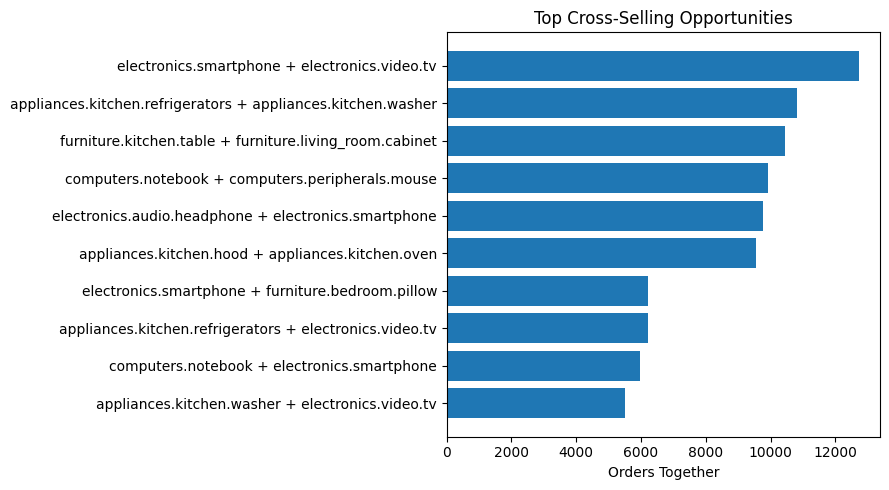

In [166]:

top_pairs = pair_data.head(10).copy()

top_pairs["Category_Pair"] = (
    top_pairs["Category_A"].astype(str)
    + " + "
    + top_pairs["Category_B"].astype(str)
)

plt.figure(figsize=(9, 5))

plt.barh(
    top_pairs["Category_Pair"],
    top_pairs["Orders_Together"]
)

plt.gca().invert_yaxis()
plt.title("Top Cross-Selling Opportunities")
plt.xlabel("Orders Together")
plt.tight_layout()
plt.show()


In [167]:

campaign_plan = pd.DataFrame([
    ["Loyal Active Customers", "Loyalty rewards", "Repeat purchase rate"],
    ["At-Risk Loyal Customers", "Win-back offer", "Reactivation rate"],
    ["Inactive-Risk Customers", "Re-engagement campaign", "Reactivation rate"],
    ["Low-Frequency Customers", "Second-purchase offer", "Second-purchase rate"],
    ["High-Value Customers", "Premium recommendations", "Revenue per customer"],
    ["Regular Customers", "Related-product suggestions", "Cross-sell conversion"]
], columns=[
    "Customer_Segment",
    "Campaign",
    "Success_KPI"
])

display(campaign_plan)


,Customer_Segment,Campaign,Success_KPI
0,Loyal Active Customers,Loyalty rewards,Repeat purchase rate
1,At-Risk Loyal Customers,Win-back offer,Reactivation rate
2,Inactive-Risk Customers,Re-engagement campaign,Reactivation rate
3,Low-Frequency Customers,Second-purchase offer,Second-purchase rate
4,High-Value Customers,Premium recommendations,Revenue per customer
5,Regular Customers,Related-product suggestions,Cross-sell conversion


In [168]:

marketing_df.to_csv(
    "customer_marketing_recommendations.csv",
    index=False
)

campaign_plan.to_csv(
    "marketing_campaign_plan.csv",
    index=False
)

print("Marketing files saved successfully.")


Marketing files saved successfully.


In [169]:

pair_data.to_csv(
    "cross_selling_analysis.csv",
    index=False
)

print("Cross-selling file saved successfully.")


Cross-selling file saved successfully.
